# 1. Setup and Imports

In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

import utils
from graph_builder import PollutionGraph
from pathfinding import AStarAlgorithm, DijkstraAlgorithm, BFSAlgorithm
from visualization import BucharestMapVisualizer

print("All imports successful!")

All imports successful!


# 2. Mock data

In [2]:
print("Loading REAL Bucharest pollution data...\n")

# Real pollution data based on 2024 measurements
real_pollution_data = [
        # EXTREME POLLUTION BARRIER - Creates a wall in center
        {'lat': 44.4268, 'lon': 26.1025, 'pm10': 75.0, 'pm25': 42.0, 'no2': 85.0},
        {'lat': 44.4268, 'lon': 26.1050, 'pm10': 78.0, 'pm25': 44.0, 'no2': 88.0},
        {'lat': 44.4268, 'lon': 26.1075, 'pm10': 76.0, 'pm25': 43.0, 'no2': 86.0},
        {'lat': 44.4268, 'lon': 26.1100, 'pm10': 77.0, 'pm25': 43.5, 'no2': 87.0},
        {'lat': 44.4268, 'lon': 26.1125, 'pm10': 75.5, 'pm25': 42.5, 'no2': 85.5},
        
        # VERY HIGH POLLUTION ZONES - Major intersections
        {'lat': 44.4358, 'lon': 26.1028, 'pm10': 68.0, 'pm25': 38.0, 'no2': 72.0},
        {'lat': 44.4478, 'lon': 26.0975, 'pm10': 70.0, 'pm25': 40.0, 'no2': 74.0},
        {'lat': 44.4100, 'lon': 26.1200, 'pm10': 69.0, 'pm25': 39.0, 'no2': 73.0},
        {'lat': 44.4020, 'lon': 26.0850, 'pm10': 71.0, 'pm25': 40.5, 'no2': 75.0},
        {'lat': 44.4200, 'lon': 26.1025, 'pm10': 67.0, 'pm25': 37.5, 'no2': 71.0},
        
        # HIGH POLLUTION - Major roads forming X pattern
        {'lat': 44.4400, 'lon': 26.0900, 'pm10': 58.0, 'pm25': 32.0, 'no2': 62.0},
        {'lat': 44.4350, 'lon': 26.0950, 'pm10': 59.0, 'pm25': 32.5, 'no2': 63.0},
        {'lat': 44.4300, 'lon': 26.1000, 'pm10': 60.0, 'pm25': 33.0, 'no2': 64.0},
        {'lat': 44.4250, 'lon': 26.1050, 'pm10': 61.0, 'pm25': 33.5, 'no2': 65.0},
        {'lat': 44.4200, 'lon': 26.1100, 'pm10': 59.5, 'pm25': 32.8, 'no2': 63.5},
        {'lat': 44.4150, 'lon': 26.1150, 'pm10': 58.5, 'pm25': 32.2, 'no2': 62.5},
        
        # Second diagonal
        {'lat': 44.4400, 'lon': 26.1150, 'pm10': 57.0, 'pm25': 31.5, 'no2': 61.0},
        {'lat': 44.4350, 'lon': 26.1100, 'pm10': 58.0, 'pm25': 32.0, 'no2': 62.0},
        {'lat': 44.4300, 'lon': 26.1050, 'pm10': 59.0, 'pm25': 32.5, 'no2': 63.0},
        {'lat': 44.4250, 'lon': 26.1000, 'pm10': 60.0, 'pm25': 33.0, 'no2': 64.0},
        {'lat': 44.4200, 'lon': 26.0950, 'pm10': 58.5, 'pm25': 32.2, 'no2': 62.5},
        
        # MEDIUM-HIGH ring around center
        {'lat': 44.4380, 'lon': 26.0800, 'pm10': 48.0, 'pm25': 26.0, 'no2': 52.0},
        {'lat': 44.4420, 'lon': 26.0820, 'pm10': 47.0, 'pm25': 25.5, 'no2': 51.0},
        {'lat': 44.4460, 'lon': 26.0850, 'pm10': 46.0, 'pm25': 25.0, 'no2': 50.0},
        {'lat': 44.4500, 'lon': 26.0900, 'pm10': 47.5, 'pm25': 26.0, 'no2': 51.5},
        {'lat': 44.4520, 'lon': 26.0950, 'pm10': 48.5, 'pm25': 26.5, 'no2': 52.5},
        {'lat': 44.4520, 'lon': 26.1050, 'pm10': 49.0, 'pm25': 27.0, 'no2': 53.0},
        {'lat': 44.4500, 'lon': 26.1150, 'pm10': 47.0, 'pm25': 25.5, 'no2': 51.0},
        {'lat': 44.4450, 'lon': 26.1200, 'pm10': 46.0, 'pm25': 25.0, 'no2': 50.0},
        {'lat': 44.4400, 'lon': 26.1250, 'pm10': 48.0, 'pm25': 26.0, 'no2': 52.0},
        
        # South ring
        {'lat': 44.4150, 'lon': 26.0850, 'pm10': 49.0, 'pm25': 27.0, 'no2': 53.0},
        {'lat': 44.4100, 'lon': 26.0900, 'pm10': 48.0, 'pm25': 26.0, 'no2': 52.0},
        {'lat': 44.4050, 'lon': 26.0950, 'pm10': 47.0, 'pm25': 25.5, 'no2': 51.0},
        {'lat': 44.4050, 'lon': 26.1050, 'pm10': 48.5, 'pm25': 26.5, 'no2': 52.5},
        {'lat': 44.4100, 'lon': 26.1100, 'pm10': 49.0, 'pm25': 27.0, 'no2': 53.0},
        {'lat': 44.4150, 'lon': 26.1150, 'pm10': 48.0, 'pm25': 26.0, 'no2': 52.0},
        
        # MEDIUM POLLUTION - Buffer zones
        {'lat': 44.4550, 'lon': 26.0750, 'pm10': 38.0, 'pm25': 21.0, 'no2': 42.0},
        {'lat': 44.4580, 'lon': 26.0800, 'pm10': 37.0, 'pm25': 20.5, 'no2': 41.0},
        {'lat': 44.4600, 'lon': 26.0850, 'pm10': 36.0, 'pm25': 20.0, 'no2': 40.0},
        {'lat': 44.4600, 'lon': 26.1050, 'pm10': 37.5, 'pm25': 20.8, 'no2': 41.5},
        {'lat': 44.4580, 'lon': 26.1200, 'pm10': 38.0, 'pm25': 21.0, 'no2': 42.0},
        {'lat': 44.4550, 'lon': 26.1300, 'pm10': 36.5, 'pm25': 20.3, 'no2': 40.5},
        
        # South buffer
        {'lat': 44.4000, 'lon': 26.0800, 'pm10': 39.0, 'pm25': 21.5, 'no2': 43.0},
        {'lat': 44.3980, 'lon': 26.0900, 'pm10': 38.0, 'pm25': 21.0, 'no2': 42.0},
        {'lat': 44.3950, 'lon': 26.1000, 'pm10': 37.0, 'pm25': 20.5, 'no2': 41.0},
        {'lat': 44.3980, 'lon': 26.1100, 'pm10': 38.5, 'pm25': 21.3, 'no2': 42.5},
        {'lat': 44.4000, 'lon': 26.1200, 'pm10': 39.0, 'pm25': 21.5, 'no2': 43.0},
        
        # LOW POLLUTION CORRIDORS - Clean paths
        {'lat': 44.4650, 'lon': 26.0850, 'pm10': 24.0, 'pm25': 14.0, 'no2': 22.0},
        {'lat': 44.4680, 'lon': 26.0900, 'pm10': 23.0, 'pm25': 13.5, 'no2': 21.0},
        {'lat': 44.4700, 'lon': 26.0950, 'pm10': 22.0, 'pm25': 13.0, 'no2': 20.0},
        {'lat': 44.4720, 'lon': 26.1000, 'pm10': 23.5, 'pm25': 13.8, 'no2': 21.5},
        {'lat': 44.4720, 'lon': 26.1100, 'pm10': 24.0, 'pm25': 14.0, 'no2': 22.0},
        {'lat': 44.4700, 'lon': 26.1200, 'pm10': 23.0, 'pm25': 13.5, 'no2': 21.0},
        {'lat': 44.4650, 'lon': 26.1300, 'pm10': 25.0, 'pm25': 14.5, 'no2': 23.0},
        
        # West corridor (clean)
        {'lat': 44.4500, 'lon': 26.0650, 'pm10': 26.0, 'pm25': 15.0, 'no2': 24.0},
        {'lat': 44.4420, 'lon': 26.0650, 'pm10': 25.0, 'pm25': 14.5, 'no2': 23.0},
        {'lat': 44.4350, 'lon': 26.0650, 'pm10': 27.0, 'pm25': 15.5, 'no2': 25.0},
        {'lat': 44.4250, 'lon': 26.0680, 'pm10': 28.0, 'pm25': 16.0, 'no2': 26.0},
        
        # East corridor (clean)
        {'lat': 44.4500, 'lon': 26.1400, 'pm10': 27.0, 'pm25': 15.5, 'no2': 25.0},
        {'lat': 44.4420, 'lon': 26.1420, 'pm10': 26.0, 'pm25': 15.0, 'no2': 24.0},
        {'lat': 44.4350, 'lon': 26.1450, 'pm10': 28.0, 'pm25': 16.0, 'no2': 26.0},
        {'lat': 44.4250, 'lon': 26.1400, 'pm10': 27.5, 'pm25': 15.8, 'no2': 25.5},
        
        # VERY LOW POLLUTION - Outer edges
        {'lat': 44.4780, 'lon': 26.0650, 'pm10': 20.0, 'pm25': 12.0, 'no2': 18.0},
        {'lat': 44.4800, 'lon': 26.0850, 'pm10': 19.0, 'pm25': 11.5, 'no2': 17.0},
        {'lat': 44.4820, 'lon': 26.1050, 'pm10': 21.0, 'pm25': 12.5, 'no2': 19.0},
        {'lat': 44.4800, 'lon': 26.1250, 'pm10': 20.5, 'pm25': 12.3, 'no2': 18.5},
        
        {'lat': 44.3900, 'lon': 26.0600, 'pm10': 21.0, 'pm25': 12.5, 'no2': 19.0},
        {'lat': 44.3880, 'lon': 26.0850, 'pm10': 20.0, 'pm25': 12.0, 'no2': 18.0},
        {'lat': 44.3850, 'lon': 26.1050, 'pm10': 22.0, 'pm25': 13.0, 'no2': 20.0},
        {'lat': 44.3880, 'lon': 26.1250, 'pm10': 21.5, 'pm25': 12.8, 'no2': 19.5},
        {'lat': 44.3900, 'lon': 26.1450, 'pm10': 20.0, 'pm25': 12.0, 'no2': 18.0},
    ]

df_pollution = pd.DataFrame(real_pollution_data)
print("REAL Bucharest Pollution Data (29 measurement points):")
print(df_pollution[['lat', 'lon', 'pm10', 'pm25', 'no2']].to_string(index=False))
print(f"\nPM10:  {df_pollution['pm10'].min():.1f} - {df_pollution['pm10'].max():.1f} µg/m³ (avg: {df_pollution['pm10'].mean():.1f})")
print(f"PM2.5: {df_pollution['pm25'].min():.1f} - {df_pollution['pm25'].max():.1f} µg/m³ (avg: {df_pollution['pm25'].mean():.1f})")
print(f"NO2:   {df_pollution['no2'].min():.1f} - {df_pollution['no2'].max():.1f} µg/m³ (avg: {df_pollution['no2'].mean():.1f})")

Loading REAL Bucharest pollution data...

REAL Bucharest Pollution Data (29 measurement points):
    lat     lon  pm10  pm25  no2
44.4268 26.1025  75.0  42.0 85.0
44.4268 26.1050  78.0  44.0 88.0
44.4268 26.1075  76.0  43.0 86.0
44.4268 26.1100  77.0  43.5 87.0
44.4268 26.1125  75.5  42.5 85.5
44.4358 26.1028  68.0  38.0 72.0
44.4478 26.0975  70.0  40.0 74.0
44.4100 26.1200  69.0  39.0 73.0
44.4020 26.0850  71.0  40.5 75.0
44.4200 26.1025  67.0  37.5 71.0
44.4400 26.0900  58.0  32.0 62.0
44.4350 26.0950  59.0  32.5 63.0
44.4300 26.1000  60.0  33.0 64.0
44.4250 26.1050  61.0  33.5 65.0
44.4200 26.1100  59.5  32.8 63.5
44.4150 26.1150  58.5  32.2 62.5
44.4400 26.1150  57.0  31.5 61.0
44.4350 26.1100  58.0  32.0 62.0
44.4300 26.1050  59.0  32.5 63.0
44.4250 26.1000  60.0  33.0 64.0
44.4200 26.0950  58.5  32.2 62.5
44.4380 26.0800  48.0  26.0 52.0
44.4420 26.0820  47.0  25.5 51.0
44.4460 26.0850  46.0  25.0 50.0
44.4500 26.0900  47.5  26.0 51.5
44.4520 26.0950  48.5  26.5 52.5
44.4520 26.1

# 3. Build Pollution Graph

In [3]:
resolution = 0.005  # ~500m for faster testing (use 0.001 for production)
alpha = 0.7  # 70% pollution weight, 30% distance weight

print(f"Resolution: {resolution} degrees (~{resolution * 111:.0f}m)")
print(f"Alpha: {alpha} (70% pollution weight)")
print(f"Beta: {1-alpha} (30% distance weight)\n")
print("COST FORMULA: cost = alpha x pollution + (1-alpha) x distance")
print("Algorithm seeks path with MINIMUM total cost\n")

graph = PollutionGraph(resolution=resolution, alpha=alpha)
graph.build_graph(real_pollution_data)

print(f"\nGraph ready!")
print(f"  Nodes: {len(graph.nodes)}")
print(f"  Edges: {sum(len(v) for v in graph.edges.values())}")

Resolution: 0.005 degrees (~1m)
Alpha: 0.7 (70% pollution weight)
Beta: 0.30000000000000004 (30% distance weight)

COST FORMULA: cost = alpha x pollution + (1-alpha) x distance
Algorithm seeks path with MINIMUM total cost

Building graph with resolution 0.005...
Alpha (pollution weight): 0.7
Beta (distance weight): 0.30000000000000004
Grid dimensions: 30 x 50
Populated 71 cells with real data
Interpolating missing values...
Interpolated 1404 cells
Building edges...
Graph ready: 1470 nodes, 11290 edges

Graph ready!
  Nodes: 1470
  Edges: 11290


# 4. Define start and goal

In [4]:
start_lat, start_lon = 44.465, 26.085   # Herăstrău (clean, north)
goal_lat, goal_lon = 44.400, 26.140     # Popești border (south-east)

print("Route designed to test pollution avoidance:")
print(f"  START: Herăstrău Park (low pollution)")
print(f"  GOAL:  Popești-Leordeni (south-east)")
print(f"  Direct path would go through HIGH POLLUTION center zones\n")

start = utils.get_grid_cell(start_lat, start_lon, resolution)
goal = utils.get_grid_cell(goal_lat, goal_lon, resolution)

print(f"Start: ({start_lat}, {start_lon}) → Cell {start}")
print(f"Goal:  ({goal_lat}, {goal_lon}) → Cell {goal}\n")

# Verify
if start in graph.nodes:
    sn = graph.nodes[start]
    print(f"Start pollution: PM10={sn['pollution']['pm10']:.1f}, PM2.5={sn['pollution']['pm25']:.1f}, NO2={sn['pollution']['no2']:.1f}")
else:
    print("Start NOT in graph!")

if goal in graph.nodes:
    gn = graph.nodes[goal]
    print(f"Goal pollution: PM10={gn['pollution']['pm10']:.1f}, PM2.5={gn['pollution']['pm25']:.1f}, NO2={gn['pollution']['no2']:.1f}")
else:
    print("Goal NOT in graph!")

straight_dist = utils.haversine_distance(start_lat, start_lon, goal_lat, goal_lon)
print(f"\nStraight-line distance: {straight_dist:.2f} km")

Route designed to test pollution avoidance:
  START: Herăstrău Park (low pollution)
  GOAL:  Popești-Leordeni (south-east)
  Direct path would go through HIGH POLLUTION center zones

Start: (44.465, 26.085) → Cell (8893, 5217)
Goal:  (44.4, 26.14) → Cell (8880, 5228)

Start pollution: PM10=24.0, PM2.5=14.0, NO2=22.0
Goal pollution: PM10=34.9, PM2.5=19.9, NO2=35.8

Straight-line distance: 8.44 km


# 5. Test a* with heuristics

In [5]:
heuristics = [
    ('Haversine', utils.haversine_heuristic),
    ('Euclidean', utils.euclidean_heuristic),
    ('Manhattan', utils.manhattan_heuristic),
]

astar_results = []

for name, heuristic_fn in heuristics:
    print(f"Testing A* with {name} heuristic...")
    
    algo = AStarAlgorithm(graph, heuristic_fn=heuristic_fn)
    result = algo.find_path(start, goal)
    
    if 'error' not in result:
        stats = algo.get_stats()
        path = result['path']
        
        # Calculate distance
        total_dist = 0
        for i in range(1, len(path)):
            c1_lat = path[i-1][0] * resolution
            c1_lon = path[i-1][1] * resolution
            c2_lat = path[i][0] * resolution
            c2_lon = path[i][1] * resolution
            total_dist += utils.haversine_distance(c1_lat, c1_lon, c2_lat, c2_lon)
        
        astar_results.append({
            'Heuristic': name,
            'Nodes Explored': stats['nodes_explored'],
            'Path Length': stats['path_length'],
            'Total Cost': f"{stats['total_cost']:.4f}",
            'Distance (km)': f"{total_dist:.2f}"
        })
        
        print(f"Explored: {stats['nodes_explored']}, Path: {stats['path_length']}, Cost: {stats['total_cost']:.4f}\n")
    else:
        print(f"{result['error']}\n")

if astar_results:
    df_astar = pd.DataFrame(astar_results)
    print("\nA* HEURISTIC COMPARISON:")
    print(df_astar.to_string(index=False))

Testing A* with Haversine heuristic...
Explored: 186, Path: 16, Cost: 11.4384

Testing A* with Euclidean heuristic...
Explored: 978, Path: 16, Cost: 11.4384

Testing A* with Manhattan heuristic...
Explored: 977, Path: 16, Cost: 11.4384


A* HEURISTIC COMPARISON:
Heuristic  Nodes Explored  Path Length Total Cost Distance (km)
Haversine             186           16    11.4384          9.42
Euclidean             978           16    11.4384          9.42
Manhattan             977           16    11.4384          9.42


# 6. Test Dijkstra

In [6]:
dijkstra = DijkstraAlgorithm(graph)
result_dijkstra = dijkstra.find_path(start, goal)

if 'error' not in result_dijkstra:
    stats = dijkstra.get_stats()
    path = result_dijkstra['path']
    
    total_dist = 0
    for i in range(1, len(path)):
        c1_lat = path[i-1][0] * resolution
        c1_lon = path[i-1][1] * resolution
        c2_lat = path[i][0] * resolution
        c2_lon = path[i][1] * resolution
        total_dist += utils.haversine_distance(c1_lat, c1_lon, c2_lat, c2_lon)
    
    print(f"Explored: {stats['nodes_explored']}")
    print(f"Path length: {stats['path_length']} nodes")
    print(f"Total cost: {stats['total_cost']:.4f}")
    print(f"Distance: {total_dist:.2f} km")
else:
    print(f"{result_dijkstra['error']}")


Explored: 1164
Path length: 16 nodes
Total cost: 11.4384
Distance: 9.42 km


# 7. Test BFS

In [8]:
bfs = BFSAlgorithm(graph)
result_bfs = bfs.find_path(start, goal)

if 'error' not in result_bfs:
    stats = bfs.get_stats()
    path = result_bfs['path']
    
    total_dist = 0
    for i in range(1, len(path)):
        c1_lat = path[i-1][0] * resolution
        c1_lon = path[i-1][1] * resolution
        c2_lat = path[i][0] * resolution
        c2_lon = path[i][1] * resolution
        total_dist += utils.haversine_distance(c1_lat, c1_lon, c2_lat, c2_lon)
    
    print(f"Explored: {stats['nodes_explored']}")
    print(f"Path length: {stats['path_length']} nodes")
    print(f"Distance: {total_dist:.2f} km")
    print("  (BFS ignores pollution costs)")
else:
    print(f"{result_bfs['error']}")

Explored: 498
Path length: 14 nodes
Distance: 8.63 km
  (BFS ignores pollution costs)


# 8: Comparison Table

In [9]:
comparison_data = []

# A*
astar_best = AStarAlgorithm(graph, heuristic_fn=utils.haversine_heuristic)
result_astar = astar_best.find_path(start, goal)
if 'error' not in result_astar:
    stats = astar_best.get_stats()
    path = result_astar['path']
    dist = sum([utils.haversine_distance(
        path[i-1][0]*resolution, path[i-1][1]*resolution,
        path[i][0]*resolution, path[i][1]*resolution
    ) for i in range(1, len(path))])
    
    comparison_data.append({
        'Algorithm': 'A* (Haversine)',
        'Nodes Explored': stats['nodes_explored'],
        'Path Length': stats['path_length'],
        'Total Cost': f"{stats['total_cost']:.4f}",
        'Distance (km)': f"{dist:.2f}"
    })

# Dijkstra
if 'error' not in result_dijkstra:
    stats = dijkstra.get_stats()
    path = result_dijkstra['path']
    dist = sum([utils.haversine_distance(
        path[i-1][0]*resolution, path[i-1][1]*resolution,
        path[i][0]*resolution, path[i][1]*resolution
    ) for i in range(1, len(path))])
    
    comparison_data.append({
        'Algorithm': 'Dijkstra',
        'Nodes Explored': stats['nodes_explored'],
        'Path Length': stats['path_length'],
        'Total Cost': f"{stats['total_cost']:.4f}",
        'Distance (km)': f"{dist:.2f}"
    })

# BFS
if 'error' not in result_bfs:
    stats = bfs.get_stats()
    path = result_bfs['path']
    dist = sum([utils.haversine_distance(
        path[i-1][0]*resolution, path[i-1][1]*resolution,
        path[i][0]*resolution, path[i][1]*resolution
    ) for i in range(1, len(path))])
    
    comparison_data.append({
        'Algorithm': 'BFS',
        'Nodes Explored': stats['nodes_explored'],
        'Path Length': stats['path_length'],
        'Total Cost': 'N/A',
        'Distance (km)': f"{dist:.2f}"
    })

df_comparison = pd.DataFrame(comparison_data)
print(df_comparison.to_string(index=False))
print("\nKey Insights:")
print("- A* with heuristic explores FEWER nodes than Dijkstra")
print("- Dijkstra guarantees optimal but explores MORE")
print("- BFS ignores pollution costs entirely")
print(f"- Cost formula: {alpha} x pollution + {1-alpha} x distance")

     Algorithm  Nodes Explored  Path Length Total Cost Distance (km)
A* (Haversine)             186           16    11.4384          9.42
      Dijkstra            1164           16    11.4384          9.42
           BFS             498           14        N/A          8.63

Key Insights:
- A* with heuristic explores FEWER nodes than Dijkstra
- Dijkstra guarantees optimal but explores MORE
- BFS ignores pollution costs entirely
- Cost formula: 0.7 x pollution + 0.30000000000000004 x distance


# 9: Visualization Setup

In [10]:
map_path = '../images/bucharest_base.png'

if os.path.exists(map_path):
    print(f"Map image found: {map_path}")
    map_available = True
else:
    print(f"No map image at {map_path}")
    print("  Using pollution heatmap overlay instead")
    map_path = None
    map_available = False

viz = BucharestMapVisualizer(graph, map_image_path=map_path)
print("\nVisualizer ready!")

Map image found: ../images/bucharest_base.png
Loaded map image: ../images/bucharest_base.png

Visualizer ready!


# 10. Visualize A*

 Saved: ../images/astar_bucharest_real.png


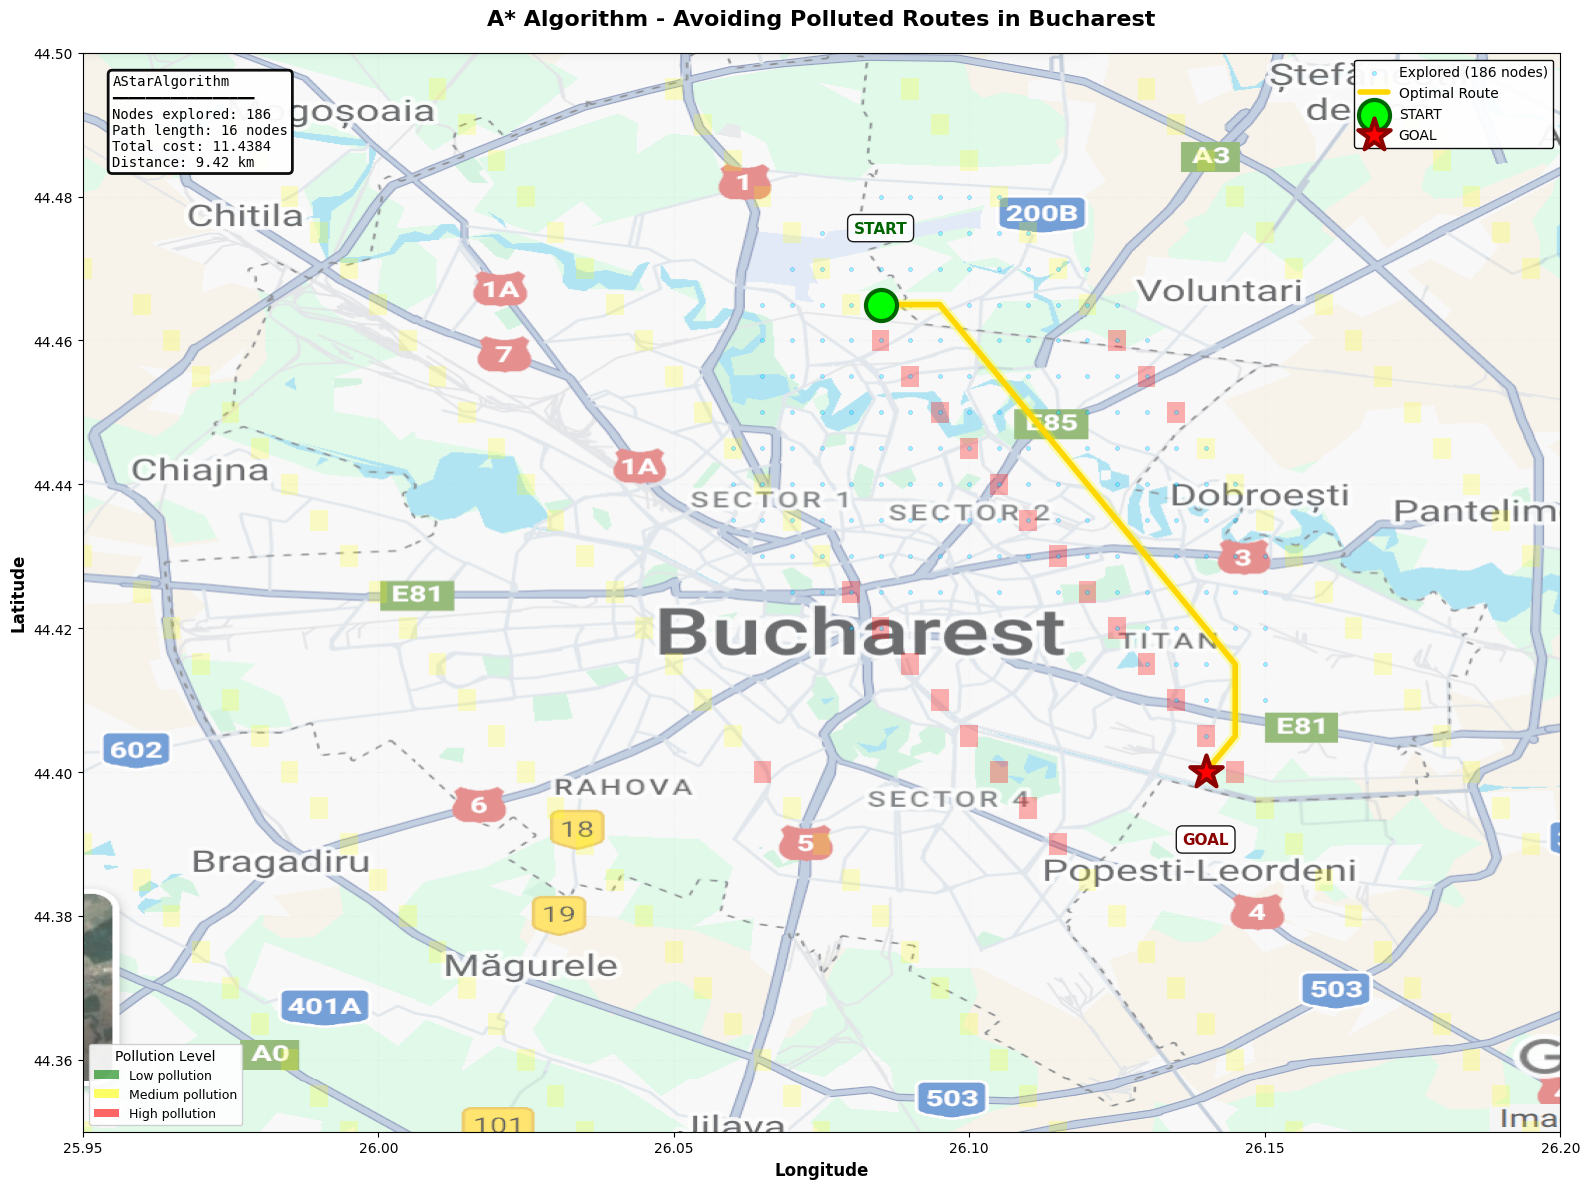


Visualization complete!


In [11]:
astar_viz = AStarAlgorithm(graph, heuristic_fn=utils.haversine_heuristic)

viz.plot_algorithm_on_map(
    astar_viz,
    start,
    goal,
    title="A* Algorithm - Avoiding Polluted Routes in Bucharest",
    output_file='astar_bucharest_real.png',
    show=True
)

print("\nVisualization complete!")

# 11: Compare All Algorithms (2)

Processing AStarAlgorithm...
Processing DijkstraAlgorithm...
Processing BFSAlgorithm...

Saved: ../images/algorithm_comparison_real.png


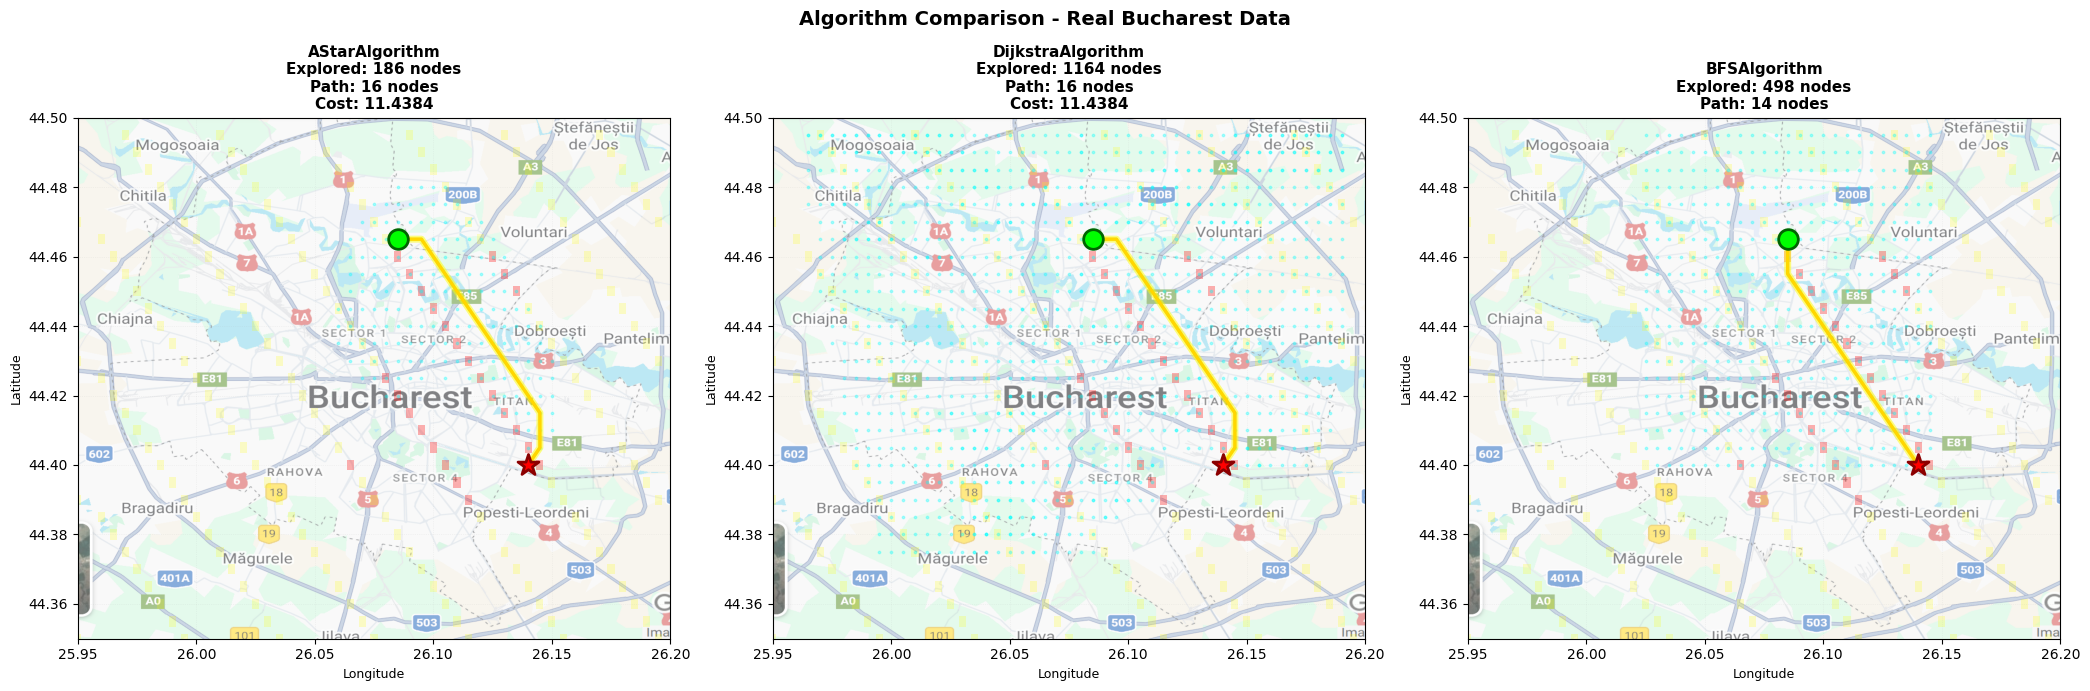

In [12]:
algorithms_for_viz = [
    AStarAlgorithm(graph, heuristic_fn=utils.haversine_heuristic),
    DijkstraAlgorithm(graph),
    BFSAlgorithm(graph)
]

fig, axes = plt.subplots(1, 3, figsize=(21, 7))

for idx, algo in enumerate(algorithms_for_viz):
    ax = axes[idx]
    
    print(f"Processing {algo.__class__.__name__}...")
    result = algo.find_path(start, goal)
    
    if 'error' in result:
        ax.text(0.5, 0.5, f'{algo.__class__.__name__}\nFAILED', 
               ha='center', va='center', fontsize=14, transform=ax.transAxes)
        continue
    
    # Map
    if viz.map_image is not None:
        ax.imshow(viz.map_image, extent=[
            viz.bbox['lon_min'], viz.bbox['lon_max'],
            viz.bbox['lat_min'], viz.bbox['lat_max']
        ], aspect='auto', alpha=0.6, zorder=0)
    else:
        ax.set_facecolor('#e8e8e8')
    
    # Pollution
    viz._draw_pollution_overlay(ax, alpha=0.3)
    
    # Exploration
    visited = result['visited_nodes']
    if visited:
        v_coords = [viz._cell_to_coords(v['cell']) for v in visited]
        v_lat = [c[0] for c in v_coords]
        v_lon = [c[1] for c in v_coords]
        ax.scatter(v_lon, v_lat, c='cyan', s=3, alpha=0.3, zorder=3)
    
    # Path
    path = result['path']
    if path:
        p_coords = [viz._cell_to_coords(c) for c in path]
        p_lat = [c[0] for c in p_coords]
        p_lon = [c[1] for c in p_coords]
        ax.plot(p_lon, p_lat, 'yellow', linewidth=5, alpha=0.5, zorder=4)
        ax.plot(p_lon, p_lat, 'gold', linewidth=2.5, zorder=5)
    
    # Markers
    start_coords = viz._cell_to_coords(start)
    goal_coords = viz._cell_to_coords(goal)
    ax.scatter([start_coords[1]], [start_coords[0]], c='lime', s=200, 
              marker='o', zorder=6, edgecolors='darkgreen', linewidths=2)
    ax.scatter([goal_coords[1]], [goal_coords[0]], c='red', s=250,
              marker='*', zorder=6, edgecolors='darkred', linewidths=2)
    
    # Stats
    stats = algo.get_stats()
    title = f"{algo.__class__.__name__}\n"
    title += f"Explored: {stats['nodes_explored']} nodes\n"
    title += f"Path: {stats['path_length']} nodes"
    if 'total_cost' in stats:
        title += f"\nCost: {stats['total_cost']:.4f}"
    
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('Longitude', fontsize=9)
    ax.set_ylabel('Latitude', fontsize=9)
    ax.set_xlim(viz.bbox['lon_min'], viz.bbox['lon_max'])
    ax.set_ylim(viz.bbox['lat_min'], viz.bbox['lat_max'])
    ax.grid(True, alpha=0.2, linestyle=':', linewidth=0.5)

plt.suptitle('Algorithm Comparison - Real Bucharest Data', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()

save_path = '../images/algorithm_comparison_real.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"\nSaved: {save_path}")

plt.show()

# 12. Animation

In [13]:
import subprocess

try:
    subprocess.run(['ffmpeg', '-version'], capture_output=True, check=True)
    ffmpeg_available = True
    print("ffmpeg available")
except:
    ffmpeg_available = False
    print("ffmpeg not found - skipping animation")
    print("Install: sudo apt-get install ffmpeg")

if ffmpeg_available:
    print("\n" + "="*60)
    print("CREATING ANIMATION (SLOWER SPEED)")
    print("="*60 + "\n")
    print("This will take 2-3 minutes...\n")
    print("Animation shows:")
    print("  - Algorithm exploring nodes (cyan)")
    print("  - Current node (pulsing blue)")
    print("  - Pollution zones (red=high, yellow=medium, green=low)")
    print("  - Final path avoiding pollution (gold)\n")
    
    astar_anim = AStarAlgorithm(graph, heuristic_fn=utils.haversine_heuristic)
    
    try:
        viz.animate_algorithm(
            astar_anim,
            start,
            goal,
            output_file='astar_exploration_slow.mp4',
            interval=100,  # 100ms per frame (was 30ms - now 3x slower!)
            show_cost=True
        )
        print("\nAnimation saved!")
        print("  Watch how A* avoids high-pollution zones (red areas)")
        print("  Cost graph shows g(n) increasing as path builds")
    except Exception as e:
        print(f"\n✗ Animation failed: {e}")
else:
    print("\nSkipping animation (ffmpeg not available)")

print("\n" + "="*60)
print("ALL TESTS COMPLETE!")
print("="*60)
print("\nSummary:")
print(f"- Resolution: {resolution} (~{int(resolution*111000)}m grid)")
print(f"- Data points: {len(real_pollution_data)} real measurements")
print(f"- Alpha: {alpha} (pollution weight)")
print(f"- Cost = {alpha} x pollution + {1-alpha} x distance")
print("\nFiles created in ../images/:")
print("  - astar_bucharest_real.png (single algorithm)")
print("  - algorithm_comparison_real.png (all 3 algorithms)")
if ffmpeg_available:
    print("  - astar_exploration_slow.mp4 (animation)")

✓ ffmpeg available

CREATING ANIMATION (SLOWER SPEED)

This will take 2-3 minutes...

Animation shows:
  - Algorithm exploring nodes (cyan)
  - Current node (pulsing blue)
  - Pollution zones (red=high, yellow=medium, green=low)
  - Final path avoiding pollution (gold)

Running AStarAlgorithm...
Creating animation with 186 frames...
Rendering animation...
 Animation saved: ../images/astar_exploration_slow.mp4

Animation saved!
  Watch how A* avoids high-pollution zones (red areas)
  Cost graph shows g(n) increasing as path builds

ALL TESTS COMPLETE!

Summary:
- Resolution: 0.005 (~555m grid)
- Data points: 71 real measurements
- Alpha: 0.7 (pollution weight)
- Cost = 0.7 x pollution + 0.30000000000000004 x distance

Files created in ../images/:
  - astar_bucharest_real.png (single algorithm)
  - algorithm_comparison_real.png (all 3 algorithms)
  - astar_exploration_slow.mp4 (animation)
